TASK 4 — **CUSTOMER SEGMENTATION VISUALIZATION**

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

onfiguration visuelle

In [ ]:
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)

In [ ]:
df = pd.read_csv("../dataset/Telco_Customer_Churn_Dataset_cleaned.csv")

In [ ]:
bins = [-1, 12, 36, 100]
labels = ['0-12 months', '13-36 months', ' +37 months']
df['tenure_group'] = pd.cut(df['tenure'], bins=bins, labels=labels)

In [ ]:
print("---Repartition des client par segment d'enciennete---")
print(df['tenure_group'].value_counts().sort_index())

---Repartition des client par segment d'enciennete---
tenure_group
0-12 months     2186
13-36 months    1856
 +37 months     3001
Name: count, dtype: int64


 DONUT CHART (Répartition des clients par ancienneté)

In [ ]:
tenure_counts = df['tenure_group'].value_counts().sort_index()

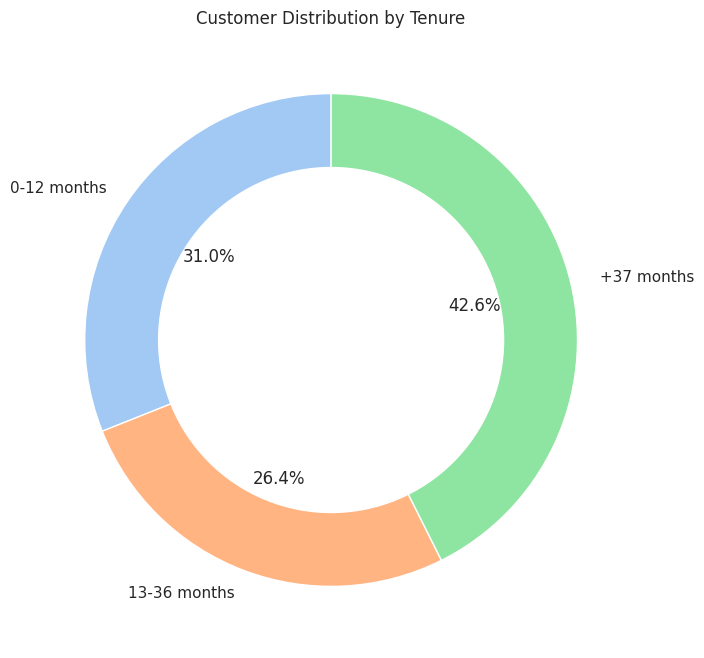

In [ ]:
plt.figure(figsize=(8, 8))
plt.pie(tenure_counts,
        labels=tenure_counts.index,
        autopct='%1.1f%%',
        startangle=90,
        colors = sns.color_palette("pastel"),
        wedgeprops={'width': 0.4, 'edgecolor': 'white'})
centre_circle = plt.Circle((0, 0), 0.70, fc='white')
fig = plt.gcf()
fig.gca().add_artist(centre_circle)

plt.title('Customer Distribution by Tenure')
plt.tight_layout
plt.show()

CLUSTERED BAR CHART

In [ ]:
avg_charges = df.groupby('tenure_group', observed=False)[['monthlycharges', 'totalcharges']].mean().reset_index

In [ ]:
print("\n--- Moyenne des charges par segment ---")
print(avg_charges)


--- Moyenne des charges par segment ---
<bound method DataFrame.reset_index of               monthlycharges  totalcharges
tenure_group                              
0-12 months        56.097781    275.229597
13-36 months       63.248195   1513.541756
 +37 months        72.008730   4213.723192>


Calcul du taux de churn par segment pour l'annotation

In [ ]:
churn_rate = df.groupby('tenure_group')['churn'].apply(lambda x: (x == 'Yes').mean() * 100)

/tmp/ipykernel_624/2552540426.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  churn_rate = df.groupby('tenure_group')['churn'].apply(lambda x: (x == 'Yes').mean() * 100)


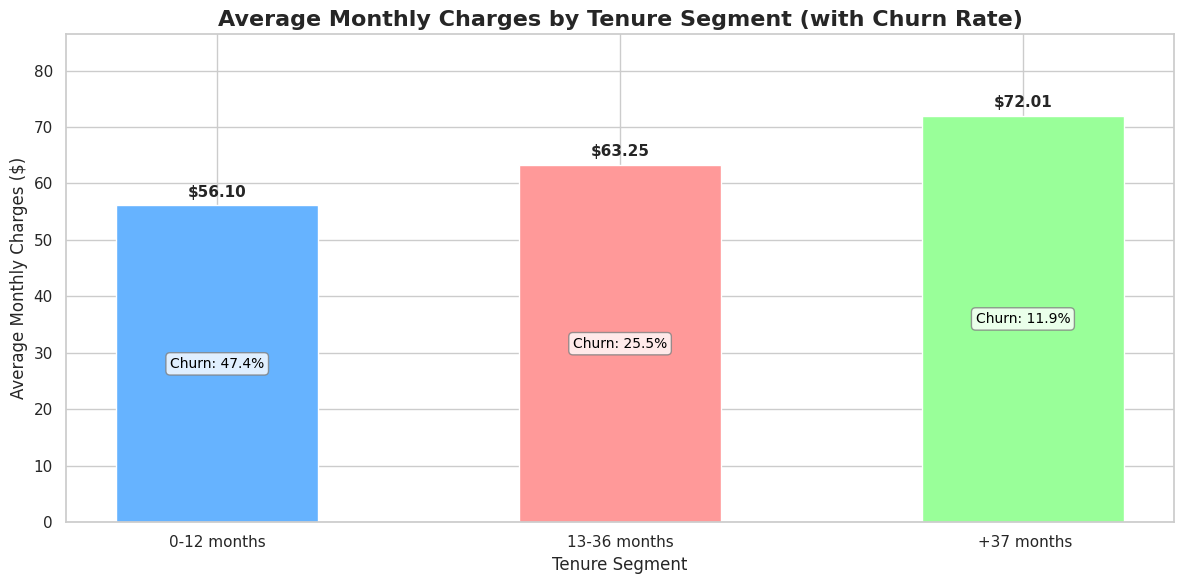

In [ ]:
churn_rate = churn_rate.reindex(labels)

avg_charges = df.groupby('tenure_group', observed=False)[['monthlycharges', 'totalcharges']].mean().reset_index()
avg_charges = avg_charges.sort_values('tenure_group')

fig, ax = plt.subplots(figsize=(12, 6))
bars = ax.bar(avg_charges['tenure_group'].astype(str), avg_charges['monthlycharges'],
              color=['#66b3ff', '#ff9999', '#99ff99'], width=0.5)

for i, bar in enumerate(bars):
    height = bar.get_height()
    category_name = avg_charges['tenure_group'].astype(str).iloc[i]

    ax.text(bar.get_x() + bar.get_width()/2., height + 1,
            f'${height:.2f}',
            ha='center', va='bottom', fontweight='bold', fontsize=11)

    churn_val = churn_rate.loc[category_name]
    ax.text(bar.get_x() + bar.get_width()/2., height/2,
            f'Churn: {churn_val:.1f}%',
            ha='center', va='center', color='black', fontsize=10,
            bbox=dict(boxstyle="round,pad=0.3", fc="white", ec="gray", alpha=0.8))

ax.set_title('Average Monthly Charges by Tenure Segment (with Churn Rate)', fontsize=16, fontweight='bold')
ax.set_xlabel('Tenure Segment', fontsize=12)
ax.set_ylabel('Average Monthly Charges ($)', fontsize=12)
ax.set_ylim(0, avg_charges['monthlycharges'].max() * 1.2)

plt.tight_layout()
plt.show()